## Pendulum

### CODE AND OUTPUT:

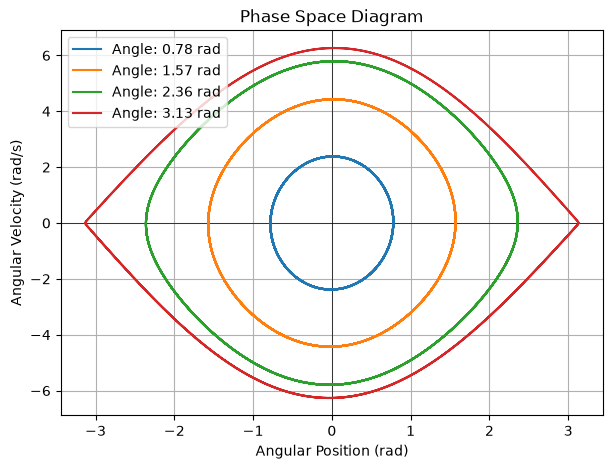

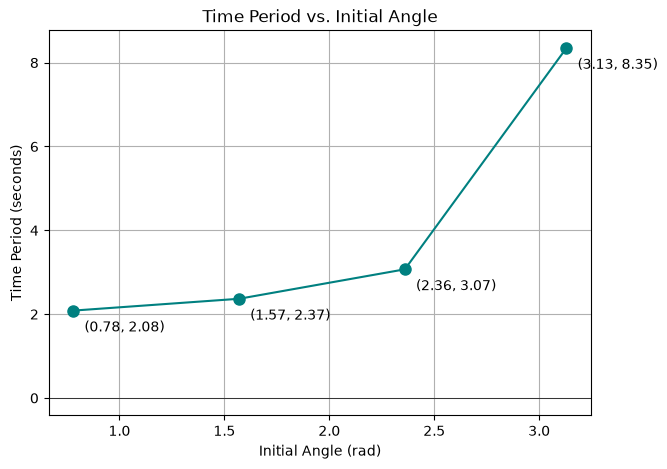

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# SETUP
g = 9.81
L = 1.0
t_max = 20.0
dt = 0.01
time_array = np.arange(0, t_max, dt)
n_steps = len(time_array)
angles_to_test = [0.78, 1.57, 2.36, 3.13]
calculated_periods = []

plt.figure(1, figsize=(7, 5))
plt.title("Phase Space Diagram")
plt.xlabel("Angular Position (rad)")
plt.ylabel("Angular Velocity (rad/s)")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(True)

for theta_0 in angles_to_test:
    theta = np.zeros(n_steps)
    omega = np.zeros(n_steps)
    theta[0] = theta_0

    # Euler-Cromer Method for calculating Angular Velocity and Angular Positions
    for i in range(1, n_steps):
        omega[i] = omega[i - 1] - (g / L) * np.sin(theta[i - 1]) * dt
        theta[i] = theta[i - 1] + omega[i] * dt
    plt.plot(theta, omega, label=f"Angle: {theta_0} rad")

    # Find Peaks
    peak_indices = []
    for i in range(1, n_steps):
        if omega[i - 1] > 0 and omega[i] <= 0:
            peak_indices.append(i)

    # Calculate Period
    if len(peak_indices) >= 2:
        peak_times = time_array[peak_indices]
        periods = np.diff(peak_times)
        avg_period = np.mean(periods)
    else:
        avg_period = 0.0
    calculated_periods.append(avg_period)

plt.legend()
plt.figure(2, figsize=(7, 5))
plt.plot(angles_to_test, calculated_periods, marker="o", markersize=8, color="teal")
for x, y in zip(angles_to_test, calculated_periods):
    plt.annotate(
        f"({x}, {y:.2f})",
        (x, y),
        textcoords="offset points",
        xytext=(8, -15),
        fontsize=10,
        ha="left",
    )
plt.title("Time Period vs. Initial Angle")
plt.xlabel("Initial Angle (rad)")
plt.ylabel("Time Period (seconds)")
plt.axhline(0, color="black", linewidth=0.5)
plt.grid(True)
plt.show()


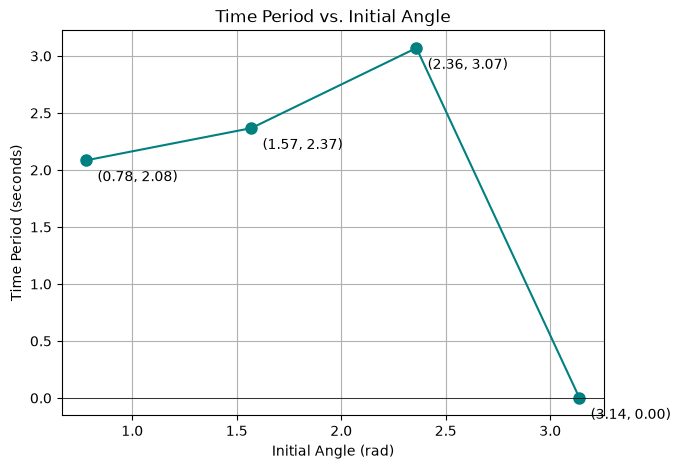

### ALGORITHM:

**Initialization and Setup**

1. Initialize the physical constants for the system: acceleration due to gravity ($g$) and the length of the pendulum ($L$).
2. Initialize the simulation parameters: the total simulation time ($t_{max}$) and the numerical time step ($dt$).
3. Generate a continuous time array starting from $0$ up to $t_{max}$ with increments of $dt$.
4. Calculate the total number of steps ($N$) based on the length of the time array.
5. Define a list of varying initial angular positions to test (`angles_to_test`) and initialize an empty list to store the resulting time periods (`calculated_periods`).

**Test Each Angle and Calculate the Time Period**

6. Initiate a loop to iterate through each angle ($\theta_0$) in the `angles_to_test` list. For each angle, perform the following sub-steps:
    
    **a.** Pre-allocate two empty arrays (filled with zeros) of size $N$ to store the angular positions ($\theta$) and angular velocities ($\omega$) for this specific run.
    
    **b.** Assign the first index (index $0$) of the $\theta$ array to the current test angle $\theta_0$. (The initial velocity remains $0.0$).
    
    **c.** *Euler-Cromer Method:* Initiate a loop from index $i = 1$ to $N - 1$. Calculate the new angular velocity, followed by the new angular position:

    $$\omega_i = \omega_{i-1} - \frac{g}{L} \sin(\theta_{i-1}) dt$$


    $$\theta_i = \theta_{i-1} + \omega_i dt$$


    **d.** Plot the current run's phase space trajectory (the $\theta$ array on the x-axis vs. the $\omega$ array on the y-axis).
    
    **e.** *Peak Detection:* Initialize an empty list to store peak indices. Initiate a loop from $i = 1$ to $N - 1$. If the previous velocity ($\omega_{i-1}$) is strictly positive and the current velocity ($\omega_i$) is less than or equal to zero, append index $i$ to the peak indices list.
    
    **f.** *Period Calculation:* Check if the peak indices list contains at least two points.

    If **true**: Extract the exact times from the time array, calculate the sequential differences between these times, and calculate the arithmetic mean of these differences 
    to find the average period ($T$).
        
    If **false**: Set $T = 0.0$.

    **g.** Append the calculated average period ($T$) to the `calculated_periods` list.

7. Plot the `angles_to_test` array on the x-axis against the `calculated_periods` array on the y-axis.

### CONCLUSIONS:

* **The Time Period is Initial Angle-Dependent:** From the "Time Period vs. Initial Angle" plot, it is clearly evident that a pendulum's time period increases as the initial release angle increases. For instance, a small initial swing of $0.78$ rad yields a time period of $2.08$ seconds, whereas an extreme swing of $3.13$ rad results in a period of $8.35$ seconds.

* **The Time Period - Initial Angle Relation is Non-Linear:** The increase in the time period is not a straight line. The curve grows relatively slowly at lower angles but spikes dramatically as the initial angle approaches $3.13$ rad (which is nearly upside down, approaching $\pi$).

* **Phase Space Geometry Warps at Larger Angles:** The "Phase Space Diagram" reveals how the physics of the pendulum changes at extremes. At a small release angle like $0.78$ rad, the trajectory of angular position versus angular velocity forms a smooth circle. However, at the extreme angle of $3.13$ rad, the trajectory distorts significantly into an "eye" shape.

* **Unstable Equilibrium at $\pi$:** At exactly $\pi$ radians, the pendulum is balanced perfectly upside down. Because the driving force of the system is proportional to $\sin(\theta)$, and $\sin(\pi) = 0$, the pendulum experiences absolutely zero angular acceleration and hence remains permanently stationary due to idealized conditions.